<a href="https://colab.research.google.com/github/BintangPancahaya/PemMes_2026/blob/main/JS09/JS09_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Tugas Lab 2: ANNOY, FAISS, dan HNSW pada Dataset Spotify
Dataset: **960K Spotify Songs With Lyrics data** (Kaggle, bwandowando) — file pertama `songs_with_attributes_and_lyrics.csv`.

### Persiapan - Install Library

In [ ]:
!pip install annoy faiss-cpu hnswlib kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 8.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 20.7 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520034 sha256=b87523f1f9401f4458b87579ab213feb4470336e16c686fb27ec9bcc86473e59
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679794 sha256=c1fc8f6cd176537e11b0e1ace6f116204b50db1e050274b0a6975736805c9637
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

### Langkah 1 - Download Dataset dan Load CSV
File CSV berukuran ±1,55 GB, jadi diunduh langsung dari Kaggle ke Colab menggunakan `kagglehub` (dataset publik).

In [ ]:
# Download dataset dari Kaggle langsung ke Colab (file pertama: songs_with_attributes_and_lyrics.csv, ±1,55 GB)
import kagglehub

csv_path = kagglehub.dataset_download(
    'bwandowando/spotify-songs-with-attributes-and-lyrics',
    path='songs_with_attributes_and_lyrics.csv'
)
print(csv_path)

Using Colab cache for faster access to the 'spotify-songs-with-attributes-and-lyrics' dataset.
/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv


In [ ]:
# Cek nama kolom yang tersedia
import pandas as pd
pd.read_csv(csv_path, nrows=3).columns.tolist()

['id',
 'name',
 'album_name',
 'artists',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'duration_ms',
 'lyrics']

### Langkah 2 - Pilih Fitur Numerik dan Normalisasi dengan StandardScaler (Boilerplate)

In [ ]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
# kolom lirik tidak dibaca agar hemat memori; ganti path sesuai lokasi file
df = pd.read_csv(csv_path, usecols=['name', 'artists'] + features)
df = df.dropna(subset=features).reset_index(drop=True)
print(df.shape)
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

(955320, 11)


In [ ]:
df.head()

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,!,HELLYEAH,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,!!,Yxngxr1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,!!! - Interlude,Glowie,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,!!De Repente!!,Rosendo,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,!!De Repente!!,Rosendo,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


### Langkah 3 - Pencarian Track Terdekat
Digunakan 1.000 lagu acak sebagai query untuk mengukur waktu rata-rata dan recall, serta 1 lagu pertama sebagai contoh hasil rekomendasi.

In [ ]:
# Query: 1 lagu untuk dilihat hasil rekomendasinya + 1000 lagu acak untuk mengukur recall & waktu
X_scaled = X_scaled.astype('float32')
rng = np.random.default_rng(42)
query_idx = rng.choice(len(X_scaled), size=1000, replace=False)
Q = X_scaled[query_idx]

contoh = query_idx[0]
print('Lagu query:', df.loc[contoh, 'name'], '-', df.loc[contoh, 'artists'])
hasil = {}

Lagu query: Get Your Body Beat - Combichrist


In [ ]:
# -------------------------------
# Exact NN (brute force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
build_time = time.time() - start

start = time.time()
_, I_exact = nn.kneighbors(Q)
query_time = (time.time() - start) * 1000 / len(Q)

hasil['Exact NN'] = (build_time, query_time, I_exact)
print(f'Build: {build_time:.3f} s | Query: {query_time:.4f} ms/query')

Build: 0.022 s | Query: 7.3327 ms/query


In [ ]:
# -------------------------------
# ANNOY
# -------------------------------
dim = X_scaled.shape[1]
annoy_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(len(X_scaled)):
    annoy_index.add_item(i, X_scaled[i])
annoy_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
I_annoy = np.array([annoy_index.get_nns_by_vector(q, k) for q in Q])
query_time = (time.time() - start) * 1000 / len(Q)

hasil['ANNOY'] = (build_time, query_time, I_annoy)
print(f'Build: {build_time:.3f} s | Query: {query_time:.4f} ms/query')

Build: 15.569 s | Query: 0.0588 ms/query


In [ ]:
# -------------------------------
# FAISS (IVF Flat)
# -------------------------------
nlist = 1000
quantizer = faiss.IndexFlatL2(dim)
faiss_index = faiss.IndexIVFFlat(quantizer, dim, nlist, faiss.METRIC_L2)

start = time.time()
faiss_index.train(X_scaled)
faiss_index.add(X_scaled)
build_time = time.time() - start

faiss_index.nprobe = 10
start = time.time()
_, I_faiss = faiss_index.search(Q, k)
query_time = (time.time() - start) * 1000 / len(Q)

hasil['FAISS'] = (build_time, query_time, I_faiss)
print(f'Build: {build_time:.3f} s | Query: {query_time:.4f} ms/query')

Build: 1.935 s | Query: 0.1699 ms/query


In [ ]:
# -------------------------------
# HNSW (hnswlib)
# -------------------------------
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=len(X_scaled), ef_construction=100, M=16)
hnsw_index.add_items(X_scaled)
build_time = time.time() - start

hnsw_index.set_ef(50)
start = time.time()
I_hnsw, _ = hnsw_index.knn_query(Q, k=k)
query_time = (time.time() - start) * 1000 / len(Q)

hasil['HNSW'] = (build_time, query_time, I_hnsw)
print(f'Build: {build_time:.3f} s | Query: {query_time:.4f} ms/query')

Build: 93.582 s | Query: 0.0374 ms/query


### Langkah 4 - Perbandingan Exact NN, ANNOY, FAISS, dan HNSW

In [ ]:
# -------------------------------
# Perbandingan performa
# -------------------------------
def recall_at_k(I_pred, I_gt):
    benar = sum(len(set(I_pred[i]) & set(I_gt[i])) for i in range(len(I_gt)))
    return benar / (len(I_gt) * k)

tabel = pd.DataFrame([
    {'Metode': nama, 'Build time (s)': round(b, 3), 'Query time (ms/query)': round(q, 4),
     'Recall@10 vs Exact': round(recall_at_k(I, I_exact), 4)}
    for nama, (b, q, I) in hasil.items()
])
tabel

,Metode,Build time (s),Query time (ms/query),Recall@10 vs Exact
0,Exact NN,0.022,7.3327,1.0000
1,ANNOY,15.569,0.0588,0.8375
2,FAISS,1.935,0.1699,0.9947
3,HNSW,93.582,0.0374,0.9963


In [ ]:
# -------------------------------
# Track terdekat untuk lagu query (baris pertama)
# -------------------------------
print('Lagu query:', df.loc[contoh, 'name'], '-', df.loc[contoh, 'artists'])
for nama, (_, _, I) in hasil.items():
    print(f'\n=== {nama} ===')
    for rank, idx in enumerate(I[0], start=1):
        print(f'{rank:2d}. {df.loc[idx, "name"]} - {df.loc[idx, "artists"]}')

Lagu query: Get Your Body Beat - Combichrist

=== Exact NN ===
 1. Get Your Body Beat - Combichrist
 2. Free Range - Live - The Fall
 3. Mega Mix - Boney M.
 4. Police At the Door - Batmobile
 5. Slave To The Music - Ferry & Garnefski Clubmix - Twenty 4 Seven
 6. Mega Mix - Radio Version - Boney M.
 7. Rivers of Babylon - Boney M.
 8. You Think You're A Man - Divine
 9. Catch Me If You Can - Hardcore Superstar
10. Catch Me If You Can - Hardcore Superstar

=== ANNOY ===
 1. Get Your Body Beat - Combichrist
 2. Free Range - Live - The Fall
 3. Mega Mix - Boney M.
 4. Police At the Door - Batmobile
 5. Slave To The Music - Ferry & Garnefski Clubmix - Twenty 4 Seven
 6. Mega Mix - Radio Version - Boney M.
 7. You Think You're A Man - Divine
 8. Catch Me If You Can - Hardcore Superstar
 9. Catch Me If You Can - Hardcore Superstar
10. Move On Baby - Original Mix - Cappella

=== FAISS ===
 1. Get Your Body Beat - Combichrist
 2. Free Range - Live - The Fall
 3. Mega Mix - Boney M.
 4. Police 

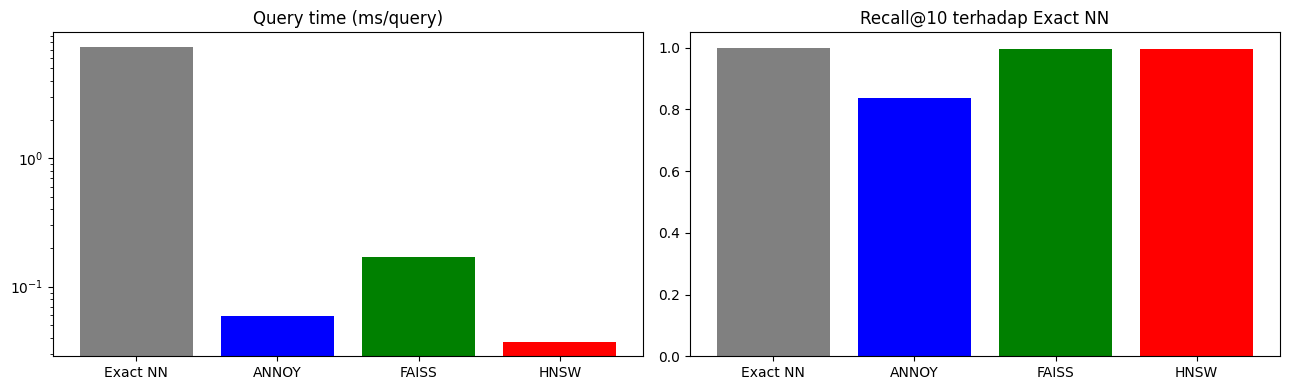

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(tabel['Metode'], tabel['Query time (ms/query)'], color=['gray', 'blue', 'green', 'red'])
axes[0].set_title('Query time (ms/query)')
axes[0].set_yscale('log')
axes[1].bar(tabel['Metode'], tabel['Recall@10 vs Exact'], color=['gray', 'blue', 'green', 'red'])
axes[1].set_title('Recall@10 terhadap Exact NN')
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Analisis Hasil

Pencarian dilakukan pada **955.320 lagu** dengan 9 fitur numerik yang sudah dinormalisasi, memakai 1.000 lagu acak sebagai query.

| Metode | Build time | Query time | Recall@10 |
|---|---|---|---|
| Exact NN | ±0,02 s | ±7,33 ms/query | 1,000 |
| ANNOY | ±15,6 s | ±0,06 ms/query | 0,838 |
| FAISS (IVF) | ±1,9 s | ±0,17 ms/query | 0,995 |
| HNSW | ±93,6 s | ±0,04 ms/query | 0,996 |

- **Exact NN** paling akurat (acuan), tetapi query-nya paling lambat karena harus menghitung jarak ke seluruh ±955 ribu lagu. Build-nya hampir nol karena brute force tidak membangun index.
- **HNSW** memberi query tercepat (±200× lebih cepat dari exact NN) dengan recall hampir sempurna (±99,6%). Kelemahannya, waktu membangun graf paling lama (±1,5 menit).
- **FAISS (IVF Flat)** paling seimbang: build cepat (±2 detik), recall ±99,5%, dan query ±40× lebih cepat dari exact NN.
- **ANNOY** juga cepat saat query, tetapi recall-nya paling rendah (±84%). Dengan 10 trees, sebagian tetangga terdekat yang sebenarnya terlewat. Recall bisa dinaikkan dengan menambah jumlah tree atau `search_k`, dengan konsekuensi lebih lambat.

**Contoh hasil rekomendasi** untuk lagu *Get Your Body Beat – Combichrist*: FAISS dan HNSW mengembalikan 10 lagu yang sama persis dengan exact NN, sedangkan ANNOY cocok 9 dari 10 (satu lagu, *Rivers of Babylon – Boney M.*, tergantikan oleh *Move On Baby – Cappella*).

**Kesimpulan:** untuk dataset besar seperti ini, metode ANN jauh lebih efisien daripada exact NN. HNSW cocok bila kecepatan query dan akurasi paling penting (index cukup dibangun sekali), FAISS cocok bila butuh build cepat dengan akurasi tinggi, sedangkan ANNOY paling ringan tetapi perlu tuning agar akurasinya setara.